In [43]:
import pandas as pd
%matplotlib inline
from tqdm.notebook import tqdm_notebook
tqdm_notebook.pandas()
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import f1_score , recall_score, accuracy_score, precision_score, confusion_matrix
from sklearn.model_selection import train_test_split
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics

In [2]:
df_train_img = pd.read_csv('../resources/t/df_train_final.csv')

df_train_img= df_train_img.drop("Unnamed: 0", axis=1)
df_train_img.head(1)

,designation,description,productid,imageid,nom_img,Texte,prdtypecode,Catégories,cat_code
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,image_1263597046_product_3804725264,olivia personalisiertes notizbuch seiten punkt...,10,Livres occasions,0


In [3]:
# Supprimer la colonne prdtypecode
df_train_img.drop(columns=['prdtypecode'], inplace=True)

# Renommer la colonne cat_code en prdtypecode
df_train_img.rename(columns={'cat_code': 'prdtypecode'}, inplace=True)


In [4]:
print(df_train_img['nom_img'].iloc[1])

image_1008141237_product_436067568


In [5]:
# L'emplacement que vous souhaitez ajouter
emplacement = '/Users/erik/Temp/Datascience_perso/projetDS/resources/t/images/image_train/'

# Fonction pour ajouter l'emplacement au nom de l'image
def ajouter_emplacement(nom_img):
    return emplacement + nom_img + ".jpg"

# Appliquer la fonction à la colonne 'nom_img'
df_train_img['nom_img'] = df_train_img['nom_img'].apply(ajouter_emplacement)

df_train_img.head()

,designation,description,productid,imageid,nom_img,Texte,Catégories,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,/Users/erik/Temp/Datascience_perso/projetDS/re...,olivia personalisiertes notizbuch seiten punkt...,Livres occasions,0
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,/Users/erik/Temp/Datascience_perso/projetDS/re...,journal arts art marche salon art asiatique pa...,"Journaux, revues d'occasion",18
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,/Users/erik/Temp/Datascience_perso/projetDS/re...,grand stylet ergonomique bleu gamepad nintendo...,accessories gaming,2
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,/Users/erik/Temp/Datascience_perso/projetDS/re...,peluche donald europe disneyland marionnette d...,Jouets petite enfance,7
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,/Users/erik/Temp/Datascience_perso/projetDS/re...,guerre tuques luc grandeur veut organiser jeu ...,Livres neufs,25


In [6]:
df_train_img["prdtypecode"] = df_train_img["prdtypecode"].astype('str')

In [7]:
df_train_img.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   designation  84916 non-null  object
 1   description  55116 non-null  object
 2   productid    84916 non-null  int64 
 3   imageid      84916 non-null  int64 
 4   nom_img      84916 non-null  object
 5   Texte        84906 non-null  object
 6   Catégories   84916 non-null  object
 7   prdtypecode  84916 non-null  object
dtypes: int64(2), object(6)
memory usage: 5.2+ MB


In [8]:
df_train_img.shape

(84916, 8)

#  Xception

#Split Train Set

In [9]:
# Split Train set 
X_train, X_test = train_test_split(df_train_img, train_size=0.8, random_state=1234)

In [10]:
display(X_train.shape)
display(X_test.shape)

(67932, 8)

(16984, 8)

#Data Generator

In [11]:
img_rows = 250
img_cols = 250
batch_size = 64
epochs = 25
emplacement = '/Users/erik/Temp/Datascience_perso/projetDS/resources/t/images/image_train/'

In [12]:
%%time
#Générateur de données
train_datagen = ImageDataGenerator(rescale = 1/255,
                                  shear_range=0.2,
                                  rotation_range = 45,
                                  width_shift_range = 0.1,
                                  height_shift_range = 0.1,
                                  zoom_range = 0.2,
                                  horizontal_flip = True,
                                  vertical_flip = True
                                  )

CPU times: user 20 µs, sys: 0 ns, total: 20 µs
Wall time: 21.9 µs


In [13]:
%%time
valid_datagen = ImageDataGenerator(rescale=1./255)

CPU times: user 18 µs, sys: 0 ns, total: 18 µs
Wall time: 20 µs


In [14]:
%%time

#Itérateur 
train_generator = train_datagen.flow_from_dataframe(dataframe = X_train,
                                              directory = '/Users/erik/Temp/Datascience_perso/projetDS/resources/t/images/image_train/',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                             
                                              target_size = (img_rows , img_cols),                                            
                                              batch_size = batch_size,                                             
                                              shuffle = True 
                                             )




# validation_split the validation batches ca be retrieved by specifying the subset as validation.
valid_generator = valid_datagen.flow_from_dataframe(dataframe = X_test, 
                                              directory = '/Users/erik/Temp/Datascience_perso/projetDS/resources/t/images/image_train/',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                        
                                              target_size = (img_rows , img_cols),                                        
                                              batch_size = batch_size, 
                                              shuffle = False
                                             )

Found 67932 validated image filenames belonging to 27 classes.
Found 16984 validated image filenames belonging to 27 classes.
CPU times: user 320 ms, sys: 886 ms, total: 1.21 s
Wall time: 1.8 s


#Xception implémentation

In [15]:
%%time
xception = Xception(weights='imagenet', include_top = False, input_shape=(img_rows,img_rows,3))
# sinon utilise ci-dessous:
#xception = Xception(weights=None, include_top = False, input_shape=(img_rows,img_rows,3))
# Bloquage du blackbone
for layer in xception.layers:
    layer.trainable = False   

2024-03-23 09:55:22.679079: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Pro
2024-03-23 09:55:22.679099: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 36.00 GB
2024-03-23 09:55:22.679104: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 13.50 GB
2024-03-23 09:55:22.679136: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2024-03-23 09:55:22.679147: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


CPU times: user 824 ms, sys: 192 ms, total: 1.02 s
Wall time: 1.09 s


#Xception Implementation - with fine tuning

In [16]:
# Débloquer la moitié du base_model 
for layer in xception.layers[-60:]:
    layer.trainable = True

In [17]:
model_Xception = Sequential()
model_Xception.add(xception)
# Ajout des couche de classification
model_Xception.add(GlobalAveragePooling2D()) 
model_Xception.add(Dense(units = 1024,activation='relu'))

model_Xception.add(Dropout(rate = 0.2))
model_Xception.add(Dense(units = 512, activation='relu'))

model_Xception.add(Dropout(rate = 0.2))
model_Xception.add(Dense(units = 27, activation='softmax'))
model_Xception.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ ?                      │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │   0 (unbuilt) │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 13,782,280 (52.58 MB)

 Non-trainable params: 7,079,200 (27.01 MB)

In [18]:
print("Base_Model length: ", len(xception.layers))
print(" Added model length: ", len( model_Xception.layers))

print('Last the last ten layers base model - Xception: \n ')  
for layer in xception.layers[-10:]:
    print("                 ", layer.name, "  " , layer.trainable)
    
print('\n Layers of built model: \n')  

for layer in model_Xception.layers:
    print("                 ", layer.name, "  " , layer.trainable)

Base_Model length:  132
 Added model length:  7
Last the last ten layers base model - Xception: 
 
                  conv2d_3    True
                  block13_pool    True
                  batch_normalization_3    True
                  add_11    True
                  block14_sepconv1    True
                  block14_sepconv1_bn    True
                  block14_sepconv1_act    True
                  block14_sepconv2    True
                  block14_sepconv2_bn    True
                  block14_sepconv2_act    True

 Layers of built model: 

                  xception    True
                  global_average_pooling2d    True
                  dense    True
                  dropout    True
                  dense_1    True
                  dropout_1    True
                  dense_2    True


#Compilation

In [19]:
%%time
# Compilation
model_Xception.compile(loss='sparse_categorical_crossentropy',  # fonction de perte
              optimizer= Adam(learning_rate= 0.0004) ,   #default lr = 0.001 # algorithme de descente de gradient
              metrics=['accuracy'],
                run_eagerly=True
                      )                    # métrique d'évaluation

CPU times: user 9.82 ms, sys: 4.19 ms, total: 14 ms
Wall time: 13.7 ms


#Callback

In [20]:
# For saving Callbacks and history results
nbr_Epochs = epochs

In [21]:
%%time

file_name = 'checkpoint_Xception_' + '_Shape_250x250_' + str(nbr_Epochs)+ 'Epochs.h5'

#Sauvegarder les meilleurs poids du modèle au cours de l'entraînement :
checkpoint = ModelCheckpoint(filepath ='../resources/generated/' + file_name + '.keras', 
                             monitor ='val_accuracy',
                             verbose = 1,
                             save_best_only = True, # (pour que le meilleur modèle ne soit pas écrasé)
                             save_weights_only = False,
                             mode ='max', #(permet de préciser si la métrique doit croître ou décroitre : ici on choisit 'min'
                                           #car la métrique est une perte à minimiser)
                             save_freq='epoch')
#Arrêter l'entraînement si le modèle n'évolue plus (très pratique pour ne pas gérer le
#nombre d'epoch) :
# A modifier pour avoir des 
early = EarlyStopping(monitor='val_loss',
                      min_delta = 0,
                      patience = 6, #(nombre d'epochs à attendre avant d'arrêter l'entraînement
                      restore_best_weights = True,
                      verbose = 1,
                      mode = 'min')


CPU times: user 23 µs, sys: 0 ns, total: 23 µs
Wall time: 25 µs


#Fit - train_generator

In [22]:
step_size_Train = train_generator.n//train_generator.batch_size
step_size_Valid = valid_generator.n//valid_generator.batch_size
print('step_size_Train : ' , step_size_Train)
print('step_size_Valid  : ' , step_size_Valid)

step_size_Train :  1061
step_size_Valid  :  265


In [23]:
import tensorflow as tf
print(f"TensorFlow has access to the following devices:\n{tf.config.list_physical_devices()}")


TensorFlow has access to the following devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [24]:
%%time

# Fit Train generator
history = model_Xception.fit(train_generator,                    
                    epochs = epochs,                   
                    steps_per_epoch = step_size_Train,
                    validation_data = valid_generator,
                    validation_steps = step_size_Valid,
                    callbacks=[checkpoint,early]
                    )

Epoch 1/25


/Users/erik/Library/Python/3.9/lib/python/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1061/1061 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4468 - loss: 1.9077
Epoch 1: val_accuracy improved from -inf to 0.58255, saving model to ../resources/generated/checkpoint_Xception__Shape_250x250_25Epochs.h5.keras
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 2204s 2s/step - accuracy: 0.4468 - loss: 1.9075 - val_accuracy: 0.5825 - val_loss: 1.3992
Epoch 2/25
   1/1061 ━━━━━━━━━━━━━━━━━━━━ 34:28 2s/step - accuracy: 0.5469 - loss: 1.4398

2024-03-23 10:33:11.452739: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/Applications/Xcode.app/Contents/Developer/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/contextlib.py:135: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(type, value, traceback)



Epoch 2: val_accuracy did not improve from 0.58255
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 2s 376us/step - accuracy: 0.5469 - loss: 1.4398 - val_accuracy: 0.5000 - val_loss: 1.6312
Epoch 3/25


2024-03-23 10:33:11.844515: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


... (28 outputs left out)

1061/1061 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7824 - loss: 0.6646
Epoch 17: val_accuracy did not improve from 0.70833
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 2255s 2s/step - accuracy: 0.7824 - loss: 0.6646 - val_accuracy: 0.6433 - val_loss: 1.3521
Epoch 18/25
   1/1061 ━━━━━━━━━━━━━━━━━━━━ 34:42 2s/step - accuracy: 0.7344 - loss: 0.6629

2024-03-23 15:28:46.235631: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Epoch 18: val_accuracy did not improve from 0.70833
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 2s 245us/step - accuracy: 0.7344 - loss: 0.6629 - val_accuracy: 0.6250 - val_loss: 1.1799
Epoch 18: early stopping
Restoring model weights from the end of the best epoch: 12.
CPU times: user 2h 34min 48s, sys: 1h 31min 50s, total: 4h 6min 38s
Wall time: 5h 32min 21s


2024-03-23 15:28:46.490709: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [26]:
# Save History results
date_result = '20240324'
filename = 'history_Xception_all_train_'+ date_result + '_Shape_250x250_'+ str(nbr_Epochs) +'Epochs'

In [28]:
path='../resources/generated/'
#convert the history.history dict to a pandas DataFrame:     
hist_df = pd.DataFrame(history.history) 

# history to json:  
hist_json_file = path + filename + '.json'
with open(hist_json_file, mode='w') as f:
    hist_df.to_json(f)

# history to csv: 
hist_csv_file = path + filename +'.csv'
with open(hist_csv_file, mode='w') as f:
    hist_df.to_csv(f)

# history to pickle file
hist_df.to_pickle(path + filename +'.pkl')

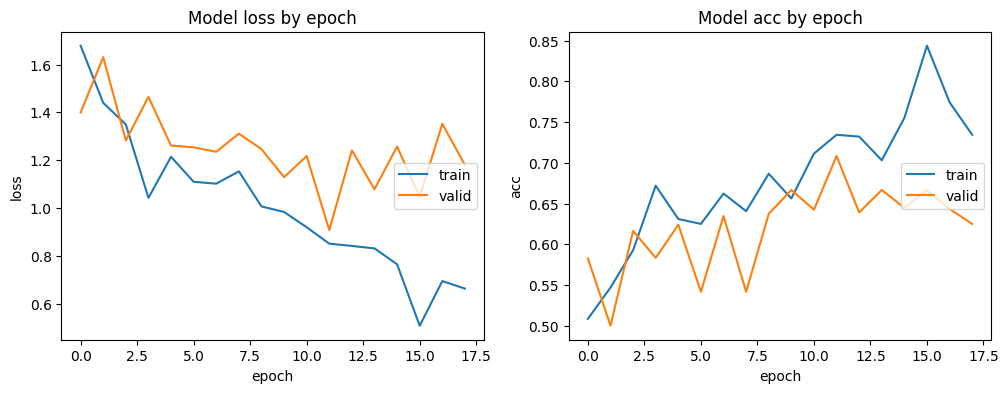

In [31]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss by epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')

plt.subplot(122)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model acc by epoch')
plt.ylabel('acc')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')
plt.show()

#Prediction test_generator

In [37]:
%%time
#Prediction - Valid set
y_pred_proba = model_Xception.predict(valid_generator)

# l'argmax pour obtenir les classes prédites
y_pred_class = np.argmax(y_pred_proba,axis = 1).astype(int)

# To get classes from test generator
y_true = valid_generator.classes

CPU times: user 670 µs, sys: 560 µs, total: 1.23 ms
Wall time: 781 µs


#Evaluation - test_generator

In [38]:
%%time
#Get the accuracy score
valid_score = model_Xception.evaluate(valid_generator)
print("[INFO] Model metrics names:", model_Xception.metrics_names)
print("[INFO] Accuracy: {:.2f}%".format(valid_score[1] * 100)) 
print("[INFO] Loss: ",valid_score[0])

266/266 ━━━━━━━━━━━━━━━━━━━━ 117s 439ms/step - accuracy: 0.6405 - loss: 1.2202
[INFO] Model metrics names: ['loss', 'compile_metrics']
[INFO] Accuracy: 64.21%
[INFO] Loss:  1.2181510925292969
CPU times: user 35.1 s, sys: 15 s, total: 50.1 s
Wall time: 1min 57s


In [39]:
f1_macro = f1_score(y_true, y_pred_class, average='macro')
print("[INFO] f1 score macro average: ",f1_macro)

f1_micro = f1_score(y_true, y_pred_class, average='micro')
print("[INFO] f1 score micro average: ",f1_micro)

f1_weighted = f1_score(y_true, y_pred_class, average='weighted')
print("[INFO] f1 score weighted average: ",f1_weighted)

[INFO] f1 score macro average:  0.595664255169453
[INFO] f1 score micro average:  0.6421337729627885
[INFO] f1 score weighted average:  0.6378531976310049


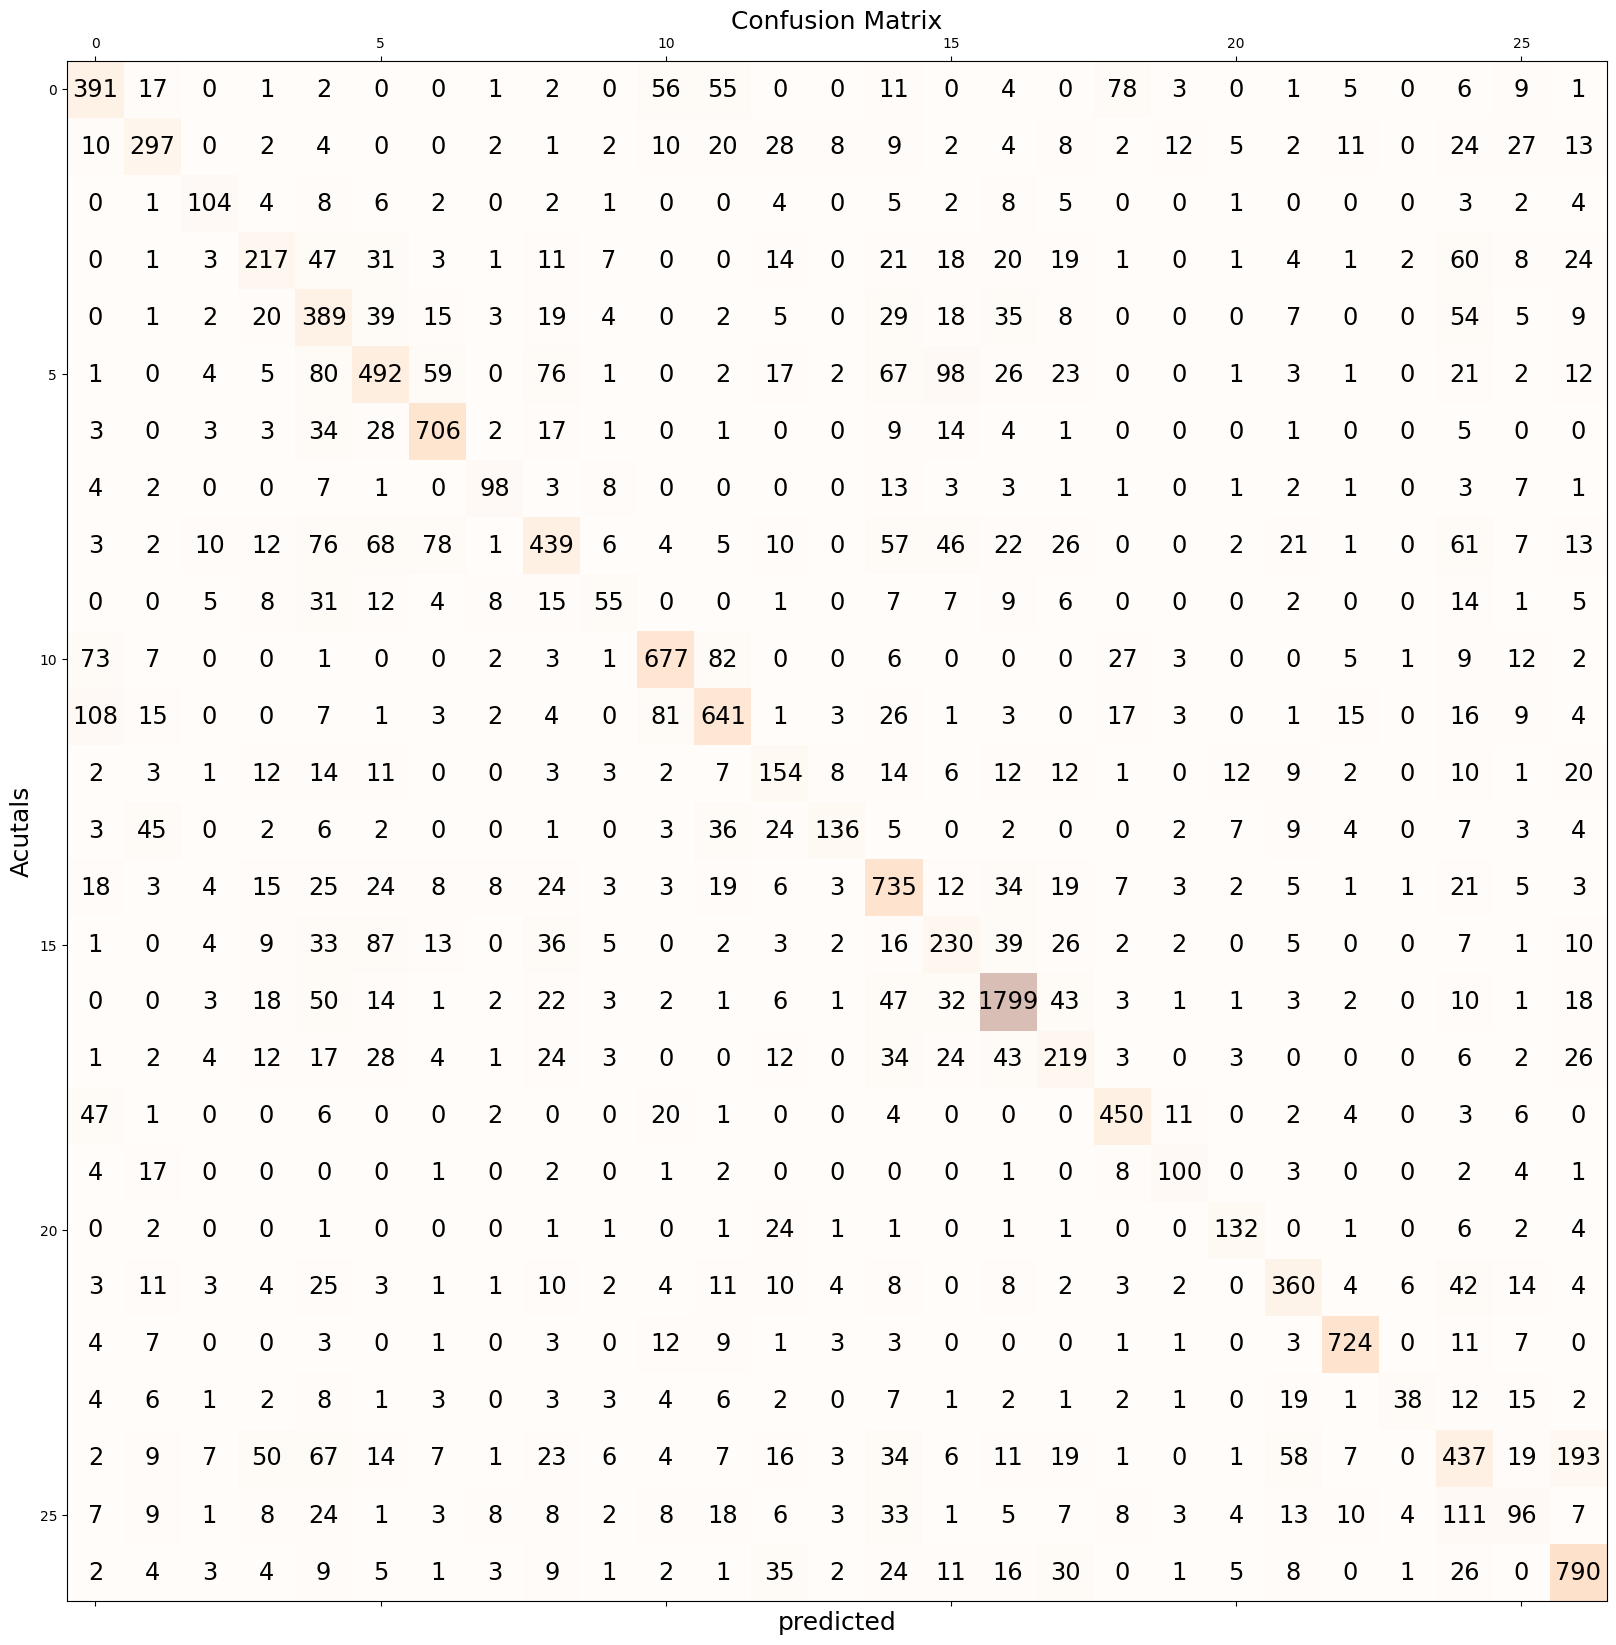

In [40]:
#Confusion matrix
matrix = confusion_matrix(y_true, y_pred_class)
fig , ax = plt.subplots(figsize = (24,20))
ax.matshow(matrix, cmap = plt.cm.Oranges , alpha = 0.3)
for i in range(matrix.shape[0]):
    for j in range (matrix.shape[1]):
        ax.text (x = j , y= i, s= matrix[i,j], va = 'center', ha = 'center', size = 'xx-large')
        
plt.xlabel('predicted', fontsize = 18)
plt.ylabel('Acutals', fontsize = 18)
plt.title('Confusion Matrix', fontsize = 18)
plt.show()
#print(matrix)

In [44]:
print(metrics.classification_report(y_true, y_pred_class))

              precision    recall  f1-score   support

           0       0.57      0.61      0.59       643
           1       0.64      0.59      0.62       503
           2       0.64      0.64      0.64       162
           3       0.53      0.42      0.47       514
           4       0.40      0.59      0.47       664
           5       0.57      0.50      0.53       993
           6       0.77      0.85      0.81       832
           7       0.67      0.62      0.64       159
           8       0.58      0.45      0.51       970
           9       0.47      0.29      0.36       190
          10       0.76      0.74      0.75       911
          11       0.69      0.67      0.68       961
          12       0.41      0.48      0.44       319
          13       0.76      0.45      0.57       301
          14       0.60      0.73      0.66      1011
          15       0.43      0.43      0.43       533
          16       0.85      0.86      0.86      2083
          17       0.46    